In [1]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D 
%matplotlib widget

from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import numpy as np
import pandas as pd

df = pd.read_excel('PRL_2024.xlsx')
df.dropna(inplace=True)
df

,Country,Code,Alcohol (2019),Coffee (2019),Fish and Seafood (2021),Poultry (2021),Beef (2021),Sheep and Goat (2021),Pig (2021),% Tobacco (2020),...,Diabetes_Class,Lung_ASR_Incidence_Class,Lung_ASR_Mortality_Class,Cervix_ASR_Inc_Class,Cervix_ASR_Mort_Class,Breast_ASR_Inc_Class,Breast_ASR _Mort_Class,Prostat_ASR_Inc_Class,Prostat_ASR_ Mort_Class,Heart_Dis_Class
0,Argentina,ARG,8.03999,1.94,6.769999,48.419990,48.489994,1.300000,15.979998,24.5,...,Very Low,Moderate,Moderate,Middle-High,Middle-High,High,Medium,Medium,Medium,Low
1,Armenia,ARM,4.98389,6.34,5.719998,19.119993,26.609991,3.869998,10.349997,25.5,...,Low,High,High,Low,Middle-Low,Low,Medium,Low,Medium,Medium
2,Australia,AUS,10.09080,5.86,24.279997,49.399994,26.339996,8.489999,25.219995,13.6,...,Low,Moderate,Moderate,Low,Low,High,Low,High,Low,Very Low
3,Austria,AUT,11.97275,9.43,14.429991,17.389988,14.189990,0.959999,43.549970,26.4,...,Very Low,High,High,Low,Low,High,Low,Medium,Low,Very Low
4,Azerbaijan,AZE,1.96779,1.18,2.010000,15.189997,12.889998,8.229999,0.820000,24.0,...,Low,Moderate,Moderate,Low,Middle-Low,Low,Very Low,Very Low,Very Low,High
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108,Thailand,THA,7.84894,0.26,28.659998,11.330000,1.450000,0.040000,13.110000,22.1,...,Moderate,Moderate,Moderate,Middle-High,Middle-Low,Low,Very Low,Very Low,Very Low,Very Low
109,Turkmenistan,TKM,2.92752,4.64,2.510000,8.570000,26.490000,20.250000,0.080000,5.5,...,Low,Low,Low,Middle-Low,Middle-High,Very Low,Medium,Very Low,Very Low,High
110,Ukraine,UKR,8.69842,1.05,13.799999,23.759998,6.340000,0.280000,17.690000,25.8,...,Low,Moderate,Moderate,Middle-High,Middle-Low,Low,Medium,High,High,High
111,Uzbekistan,UZB,2.60223,0.48,3.960000,6.469999,30.419998,4.969999,0.160000,17.6,...,Low,Low,Low,Middle-High,Middle-High,High,Medium,High,Medium,High


In [2]:
# Divide Cervix ASR Incidence to Low, Middle-Low, Middle-High, High
df['Cervix_ASR_Inc_Class'] = pd.qcut(df['Cervix Uteri Cancer Inc'], 4, labels=['Low', 'Middle-Low', 'Middle-High', 'High'])

In [3]:
X = df.drop(['Country', 'Code', 'HDI', 'Breast Cancer Inc', 'Breast Cancer Mort',
       'Lung Cancer Inc', 'Lung Cancer Mort', 'Prostat Cancer Inc',
       'Prostat Cancer Mort', 'Heart Disease Death',  'Diabetes Prevalence',
       'Cervix Uteri Cancer Inc', 'Cervix Uteri Cancer Mort', 'HDI_Class',
       'GDP_Class', 'Fertility_Rate_Class', 'Sugar_Class', 'Alcohol_Class',
       'Coffee_Class', 'Fish_Seafood_Class', 'Poultry_Class', 'Beef_Class',
       'Sheep_Goat_Class', 'Pig_Class', 'Tobacco_Class', 'Milk_Class',
       'Salt_Class', 'Vegetable_Class', 'Diabetes_Class',
       'Lung_ASR_Incidence_Class', 'Lung_ASR_Mortality_Class',
       'Cervix_ASR_Inc_Class', 'Cervix_ASR_Mort_Class', 'Breast_ASR_Inc_Class',
       'Breast_ASR _Mort_Class', 'Prostat_ASR_Inc_Class',
       'Prostat_ASR_ Mort_Class', 'Heart_Dis_Class'], axis=1)

In [4]:
X.columns = X.columns.astype(str)
y = df['Cervix_ASR_Inc_Class']
y = df['Cervix_ASR_Inc_Class'].apply(lambda x: {'Low': 0, 'Middle-Low': 1, 'Middle-High': 2, 'High': 3}[x])
target_names=['Low', 'Middle-Low', 'Middle-High', 'High']

In [5]:
# Apply standard scaler
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA(n_components=13)
X_r = pca.fit(X_scaled).transform(X_scaled)

In [6]:
import numpy as np
theta = np.arccos(np.dot([1,2,3], [4,5,6]) / (np.linalg.norm([1,2,3]) * np.linalg.norm([4,5,6])))
theta

0.2257261285527342

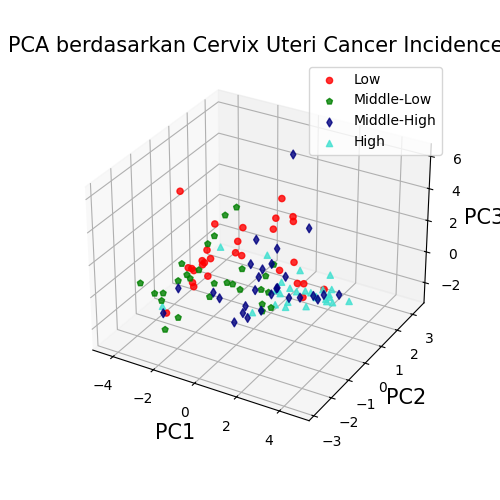

In [7]:
colors = ['red', 'green', 'navy', 'turquoise']
fig = plt.figure(1, figsize=(5, 5))
# set fontsize of title and axis
ax = fig.add_subplot(111, projection="3d")
for color, i, target_name, shape in zip(colors, [0, 1, 2, 3], target_names, ['o', 'p', 'd', '^']):
    ax.scatter(X_r[y == i, 0], X_r[y == i, 1], X_r[y == i, 2], color=color, alpha=.8, label=target_name, lw=1, marker=shape)
ax.legend(loc='best', shadow=False, scatterpoints=1)
ax.set_title("PCA berdasarkan Cervix Uteri Cancer Incidence", fontsize=15)
ax.set_xlabel('PC1', fontsize=15)
ax.set_ylabel('PC2',fontsize=15)
ax.set_zlabel('PC3', fontsize=15)
plt.show()

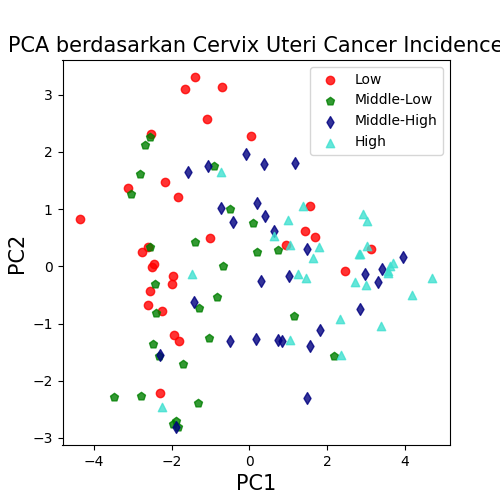

In [8]:
colors = ['red', 'green', 'navy', 'turquoise']
fig = plt.figure(20, figsize=(5, 5))
ax = fig.add_subplot(111)
for color, i, target_name, shape in zip(colors, [0, 1, 2, 3], target_names, ['o', 'p', 'd', '^']):
    ax.scatter(X_r[y == i, 0], X_r[y == i, 1], color=color, alpha=.8, label=target_name, lw=1, marker=shape)
ax.legend(loc='best', shadow=False, scatterpoints=1)
ax.set_title("PCA berdasarkan Cervix Uteri Cancer Incidence", fontsize=15)
ax.set_xlabel('PC1', fontsize=15)
ax.set_ylabel('PC2', fontsize=15)
plt.show()

In [9]:
#Calculate loadings
loadings=pca.components_.T * np.sqrt(pca.explained_variance_ratio_)

In [10]:
# Make PCA Loadings table from PC1 to PC3
loadingsdf = pd.DataFrame(loadings[:,0:3], index=X.columns, columns=['PC1', 'PC2', 'PC3'])
loadingsdf['absPC1'] = np.abs(loadingsdf['PC1'])
loadingsdf['absPC2'] = np.abs(loadingsdf['PC2'])
loadingsdf['absPC3'] = np.abs(loadingsdf['PC3'])
loadingsdf = loadingsdf.sort_values(by='absPC1', ascending=False)
loadingsdf = loadingsdf.drop('absPC1', axis=1)
loadingsdf = loadingsdf.drop('absPC2', axis=1)
loadingsdf = loadingsdf.drop('absPC3', axis=1)
loadingsdf.to_excel('loadingsdf.xlsx')

Text(0.5, 1.0, 'Plot Cumulative Explained Variance Ratio dari PCA terhadap Data Cervix Uteri Cancer Incidence')

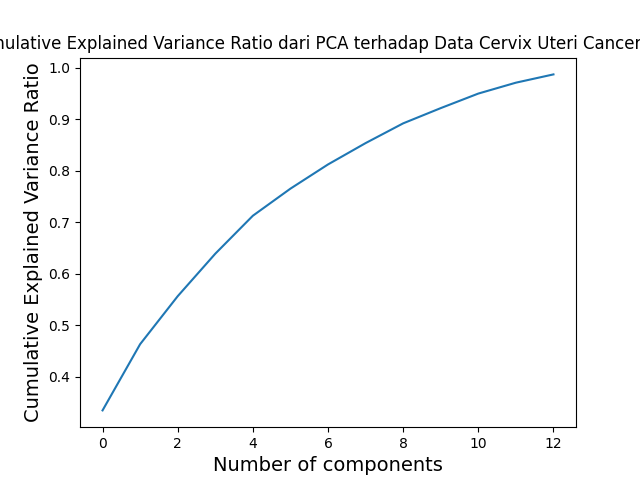

In [11]:
# Plot Cummulative Variance of PCA
plt.figure()
plt.plot(range(0,13),np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Number of components', fontsize=14)
plt.ylabel('Cumulative Explained Variance Ratio', fontsize=14)
plt.title('Plot Cumulative Explained Variance Ratio dari PCA terhadap Data Cervix Uteri Cancer Incidence')

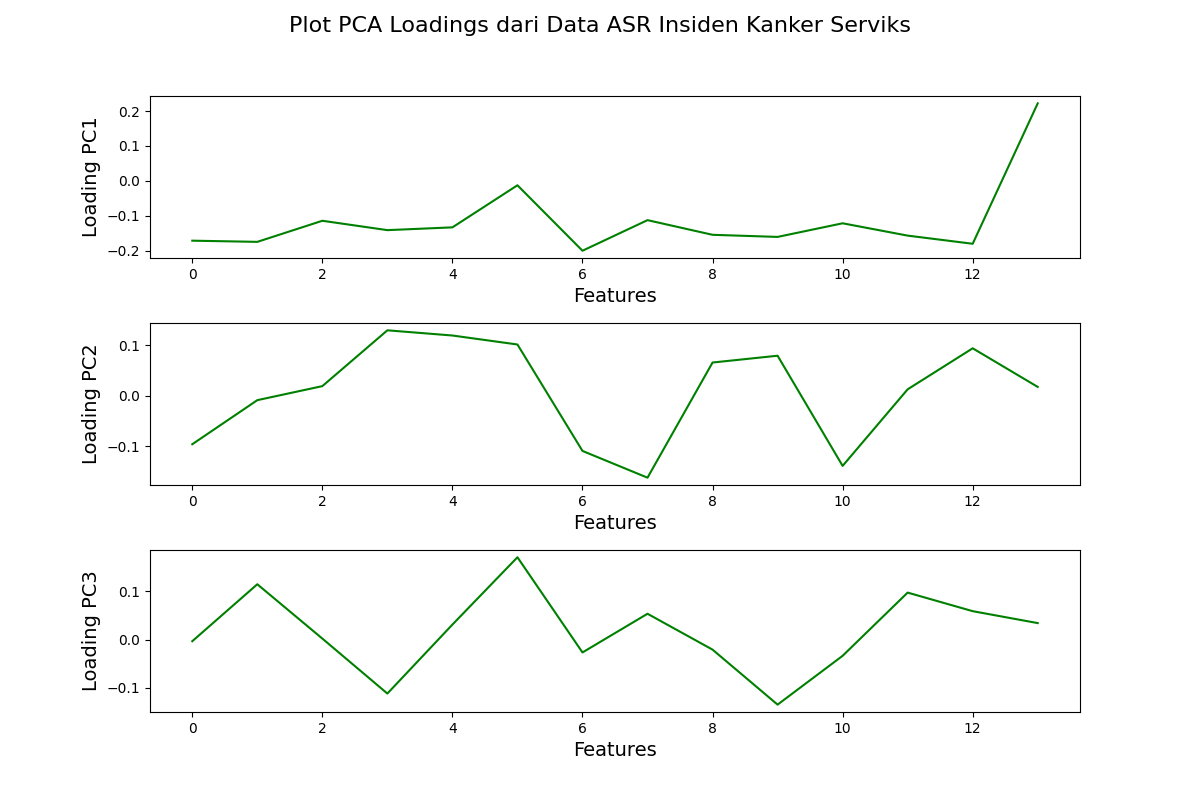

In [12]:
# """ Plot PCA loadings """
#Show loadings
# set gap between plot
fig, ax = plt.subplots(figsize=(12, 8), nrows=3, ncols=1)
fig.subplots_adjust(hspace=0.4, wspace=1)

# set title in whole figure
fig.suptitle('Plot PCA Loadings dari Data ASR Insiden Kanker Serviks', fontsize=16)

for i in range(3):
    ax[i].plot(np.arange(14),loadings[:,i],c='g')
    ax[i].set_xlabel('Features', fontsize=14)
    ax[i].set_ylabel(f'Loading PC{i+1}', fontsize=14)

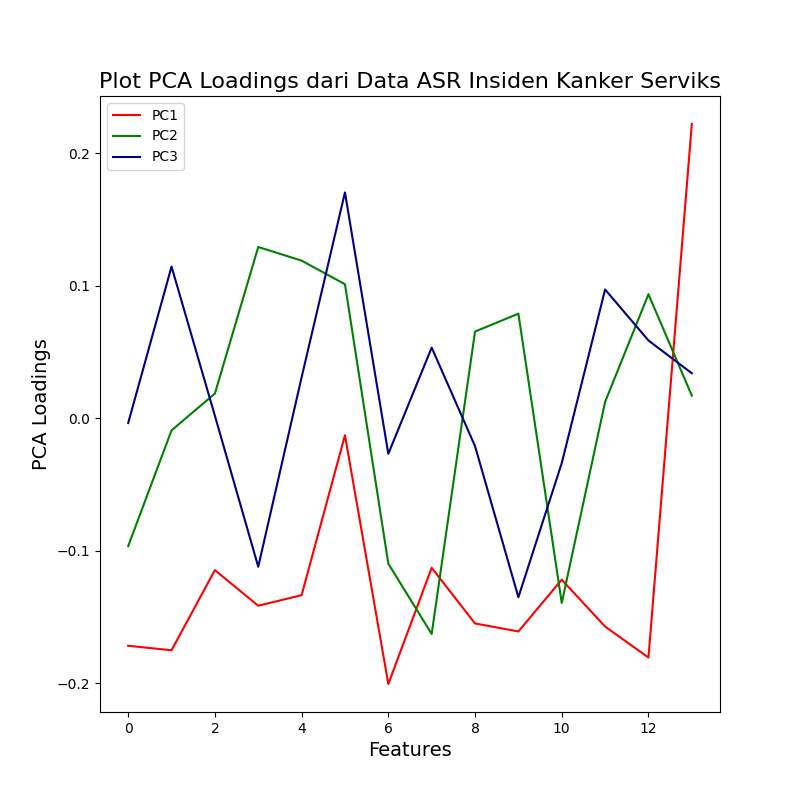

In [13]:
# Merge pca loadings in one plot
plt.figure(27, figsize=(8, 8))
plt.title('Plot PCA Loadings dari Data ASR Insiden Kanker Serviks', fontsize=16)
for i in range(3):
    plt.plot(np.arange(14),loadings[:,i],c=colors[i], label=f'PC{i+1}')
    plt.xlabel('Features', fontsize=14)
    plt.ylabel('PCA Loadings', fontsize=14)
plt.legend()
plt.show()

In [14]:
# import tools from ANOVA
from sklearn.feature_selection import f_classif
f_val, p_val = f_classif(X, y)
f_val_df = pd.DataFrame({'F-value': f_val, 'p-value': p_val}, index=X.columns)


In [15]:
f_val_df.sort_values(by='p-value').to_excel('f_val_df.xlsx')

In [16]:
f_val_df.sort_values(by='p-value')

,F-value,p-value
Fertility Rate,21.710851,4.248892e-11
GDP per Capita,17.730888,1.915957e-09
Pig (2021),11.929926,8.149426e-07
Salt (2023),10.503986,3.993293e-06
Vegetable (2021),9.968988,7.329171e-06
Sugar (2020),9.960022,7.404517e-06
Coffee (2019),8.081361,6.556492e-05
Milk (2021),6.774934,3.122705e-04
Poultry (2021),5.062344,2.545001e-03
Beef (2021),4.993793,2.771035e-03


In [17]:
# Divide data to target and features
X_baru = df[f_val_df[f_val_df['p-value'] < 0.05].index]
X_baru.columns = X_baru.columns.astype(str)
y_baru = df['Cervix_ASR_Inc_Class']
target_names = ['Low', 'High']
y_baru = df['Cervix_ASR_Inc_Class'].apply(lambda x: {'Low': 'Low', 'Middle-Low': 'Low', 'Middle-High': 'High', 'High': 'High'}[x]).apply(lambda x: {'Low': 0, 'High': 1}[x])

# Apply standard scaler
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_baru_scaled = scaler.fit_transform(X_baru)

# Apply PCA
pca_baru = PCA(n_components=13)
X_baru_r = pca_baru.fit(X_baru_scaled).transform(X_baru_scaled)

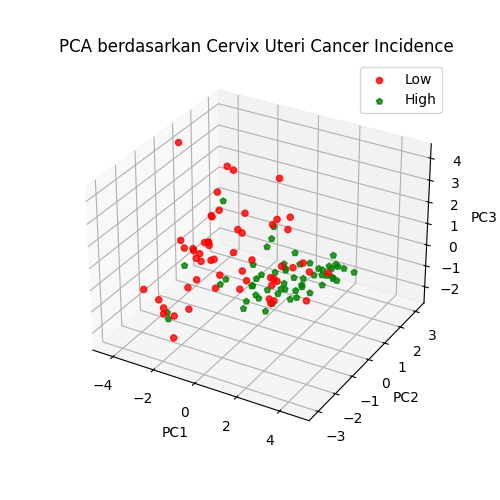

In [18]:
# Plot pca
colors = ['red', 'green']
fig = plt.figure(5, figsize=(5, 5))
ax = fig.add_subplot(111, projection="3d")
for color, i, target_name, shape in zip(colors, [0,1], target_names, ['o', 'p', 'd', '^']):
    ax.scatter(X_baru_r[y_baru == i, 0], X_baru_r[y_baru == i, 1], X_baru_r[y_baru == i, 2], color=color, alpha=.8, label=target_name, lw=1, marker=shape)
ax.legend(loc='best', shadow=False, scatterpoints=1)
ax.set_title("PCA berdasarkan Cervix Uteri Cancer Incidence")
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
plt.show()

In [19]:

#Calculate loadings
loadings_baru=pca_baru.components_.T * np.sqrt(pca_baru.explained_variance_ratio_)

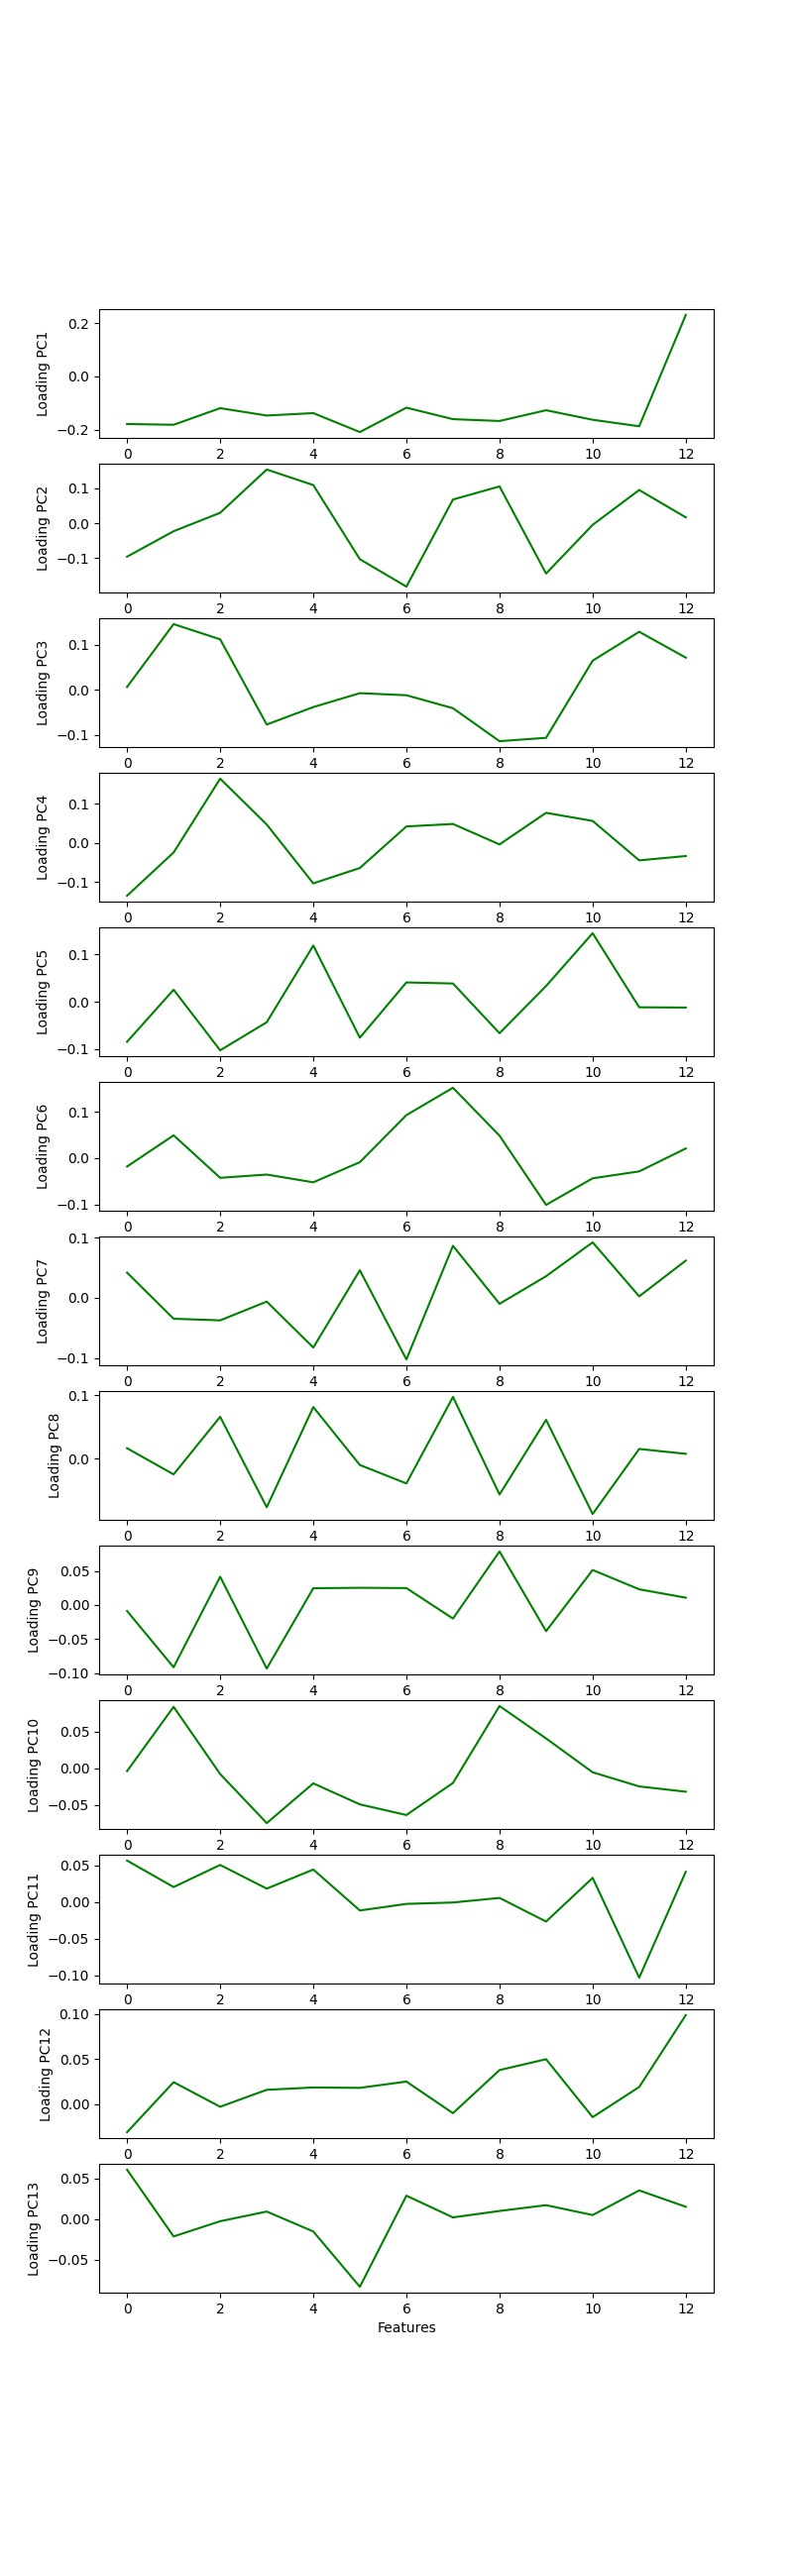

In [20]:
# """ Plot PCA loadings """
#Show loadings
fig, ax = plt.subplots(figsize=(8,26), nrows=13, ncols=1)

for i in range(13):
    ax[i].plot(np.arange(len(X_baru.columns)),loadings_baru[:,i],c='g')
    ax[i].set_xlabel('Features')
    ax[i].set_ylabel(f'Loading PC{i+1}')

Text(0, 0.5, 'Cumulative explained variance')

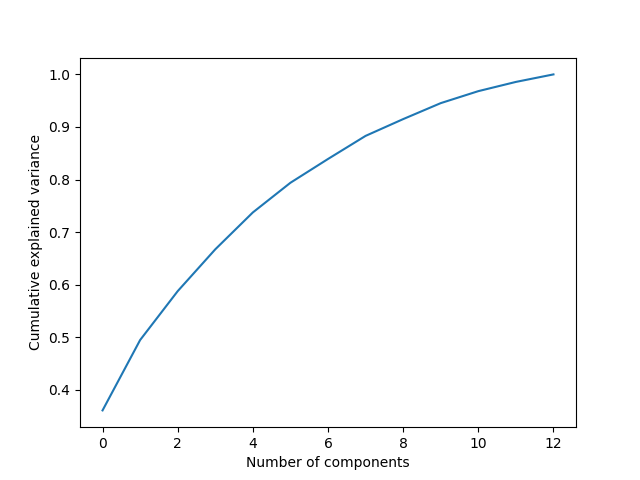

In [21]:
# Plot Cummulative Variance of PCA
plt.figure()
plt.plot(range(0,13),np.cumsum(pca_baru.explained_variance_ratio_))
plt.xlabel('Number of components')
plt.ylabel('Cumulative explained variance')